In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Загрузка данных
df = pd.read_csv('olympiad_results.csv')

# 2. Удаление полных дубликатов
df_clean = df.drop_duplicates().copy()

# 3. Приведение названий регионов к стандарту
region_mapping = {
    'г.Казань': 'Казань',
    'казань': 'Казань',
    'СПб': 'Санкт-Петербург',
    'Санкт Петербург': 'Санкт-Петербург',
    'спб': 'Санкт-Петербург',
    'мск': 'Москва',
    'москва': 'Москва',
    'г. Москва': 'Москва',
    'Moskva': 'Москва',
}
df_clean['region'] = df_clean['region'].replace(region_mapping)

# 4. Расчет длительности сессии и отсечение аномалий (< 60 сек)
df_clean['start_time'] = pd.to_datetime(df_clean['start_time'])
df_clean['end_time'] = pd.to_datetime(df_clean['end_time'])
df_clean['duration_sec'] = (
    df_clean['end_time'] - df_clean['start_time']
).dt.total_seconds()
df_clean['duration_min'] = df_clean['duration_sec'] / 60

df_clean = df_clean[df_clean['duration_sec'] >= 60].copy()

print(f'Данные готовы к анализу. Строк: {df_clean.shape[0]}')

Данные готовы к анализу. Строк: 7928


In [2]:
# Список колонок с правильными ответами и временем
task_corr_cols = [f'Task_{i}_correct' for i in range(1, 13)]
task_time_cols = [f'Task_{i}_time_spent' for i in range(1, 13)]

# 1. Считаем, на сколько заданий ученик дал ответ (пропуски NaN не считаем)
df_clean['tasks_attempted'] = df_clean[task_corr_cols].notna().sum(axis=1)

# 2. Среднее время на одну решённую/попытанную задачу (в секундах)
df_clean['avg_task_time_sec'] = (
    df_clean['duration_sec'] / df_clean['tasks_attempted']
)

# 3. Процент успешности ученика (от всех 12 задач)
df_clean['score_rate'] = (df_clean['total_score'] / 12) * 100

print(
    'Средний балл по олимпиаде:', round(df_clean['total_score'].mean(), 2)
)
print(
    'Медианное время прохождения (мин):',
    round(df_clean['duration_min'].median(), 1),
)
print(
    'Среднее количество выполненных задач:',
    round(df_clean['tasks_attempted'].mean(), 1),
)

Средний балл по олимпиаде: 5.55
Медианное время прохождения (мин): 14.2
Среднее количество выполненных задач: 11.5


Таблица сложности задач (от простых к сложным):
   Задание  Решаемость (%)  Среднее время (сек)
0       №5            61.5                 81.2
1       №8            57.4                 79.5
2       №4            56.9                 78.8
3       №7            56.5                 79.1
4      №12            54.9                 77.8
5      №10            51.1                 75.9
6      №11            45.0                 72.8
7       №6            43.2                 71.7
8       №2            36.2                 69.1
9       №3            32.6                 66.0
10      №9            30.7                 65.9
11      №1            28.6                 64.1


/tmp/ipykernel_661/1000784520.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


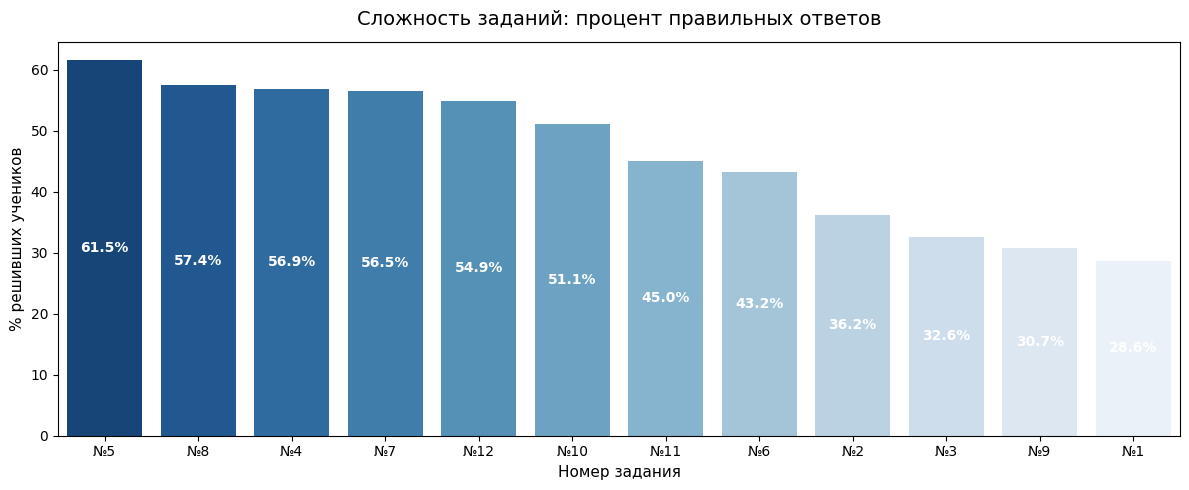

In [3]:
task_metrics = []

for i in range(1, 13):
  corr_col = f'Task_{i}_correct'
  time_col = f'Task_{i}_time_spent'

  attempted = df_clean[corr_col].notna().sum()
  solved = (df_clean[corr_col] == 1).sum()
  solve_rate = (solved / len(df_clean)) * 100
  avg_time = df_clean[time_col].mean()

  task_metrics.append({
      'Задание': f'№{i}',
      'Попыток': attempted,
      'Решено верно': solved,
      'Решаемость (%)': round(solve_rate, 1),
      'Среднее время (сек)': round(avg_time, 1),
  })

tasks_df = (
    pd.DataFrame(task_metrics)
    .sort_values('Решаемость (%)', ascending=False)
    .reset_index(drop=True)
)
print('Таблица сложности задач (от простых к сложным):')
print(tasks_df[['Задание', 'Решаемость (%)', 'Среднее время (сек)']])

# График сложности задач
fig, ax1 = plt.subplots(figsize=(12, 5))

sns.barplot(
    data=tasks_df,
    x='Задание',
    y='Решаемость (%)',
    ax=ax1,
    palette='Blues_r',
    order=tasks_df['Задание'],
)
ax1.set_title(
    'Сложность заданий: процент правильных ответов', fontsize=14, pad=12
)
ax1.set_ylabel('% решивших учеников', fontsize=11)
ax1.set_xlabel('Номер задания', fontsize=11)

for p in ax1.patches:
  ax1.annotate(
      f"{p.get_height():.1f}%",
      (p.get_x() + p.get_width() / 2.0, p.get_height() / 2),
      ha='center',
      va='center',
      color='white',
      fontweight='bold',
  )

plt.tight_layout()
plt.show()

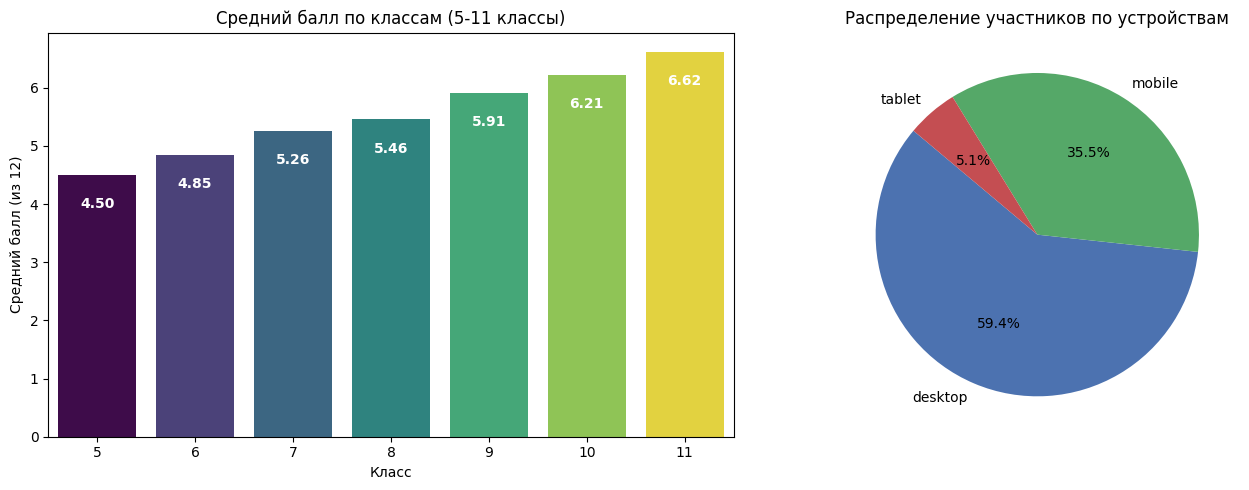

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Успеваемость по классам
grade_agg = (
    df_clean.groupby('grade')['total_score']
    .agg(['count', 'mean'])
    .reset_index()
)
sns.barplot(
    data=grade_agg,
    x='grade',
    y='mean',
    ax=axes[0],
    palette='viridis',
    hue='grade',
    legend=False,
)
axes[0].set_title('Средний балл по классам (5-11 классы)', fontsize=12)
axes[0].set_ylabel('Средний балл (из 12)')
axes[0].set_xlabel('Класс')
for p in axes[0].patches:
  axes[0].annotate(
      f'{p.get_height():.2f}',
      (p.get_x() + p.get_width() / 2.0, p.get_height() - 0.5),
      ha='center',
      va='center',
      color='white',
      fontweight='bold',
  )

# 2. Доли устройств
device_counts = df_clean['device_type'].value_counts()
axes[1].pie(
    device_counts,
    labels=device_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#4C72B0', '#55A868', '#C44E52'],
)
axes[1].set_title('Распределение участников по устройствам', fontsize=12)

plt.tight_layout()
plt.show()

  АНАЛИТИЧЕСКИЙ МИНИ-ОТЧЁТ: МОСКВА
• Всего участников: 824 чел.
• Средний балл: 5.66 из 12 (медиана: 6.0)
• Среднее время прохождения: 14.1 мин.

ТОП-5 ШКОЛ РЕГИОНА ПО СРЕДНЕМУ БАЛЛУ:


,участников,средний_балл
school_number,,
26,10,7.50
4,14,7.36
43,12,6.83
34,19,6.79
28,16,6.75


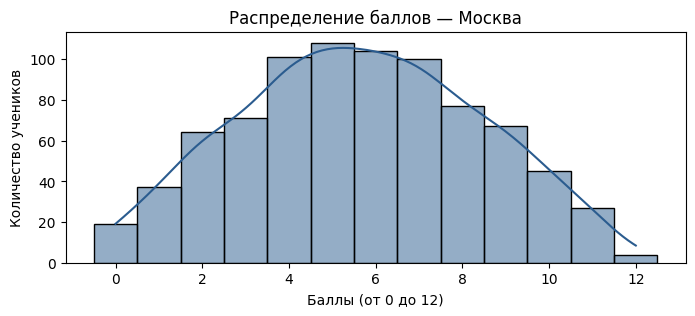

In [5]:
def generate_region_report(df, region_name):
  """Формирует аналитическую сводку и топ школ для указанного региона."""
  reg_df = df[df['region'] == region_name]

  if len(reg_df) == 0:
    print(f"Регион '{region_name}' не найден в датасете!")
    return

  total_students = len(reg_df)
  mean_score = reg_df['total_score'].mean()
  median_score = reg_df['total_score'].median()
  avg_time = reg_df['duration_min'].mean()
  top_schools = (
      reg_df.groupby('school_number')['total_score']
      .agg(участников='count', средний_балл='mean')
      .query('участников >= 5')  # фильтруем школы, где хотя бы 5 участников
      .sort_values(by='средний_балл', ascending=False)
      .head(5)
      .round(2)
  )

  print(f'{"="*40}')
  print(f'  АНАЛИТИЧЕСКИЙ МИНИ-ОТЧЁТ: {region_name.upper()}')
  print(f'{"="*40}')
  print(f'• Всего участников: {total_students} чел.')
  print(
      f'• Средний балл: {mean_score:.2f} из 12 (медиана: {median_score:.1f})'
  )
  print(f'• Среднее время прохождения: {avg_time:.1f} мин.')
  print('\nТОП-5 ШКОЛ РЕГИОНА ПО СРЕДНЕМУ БАЛЛУ:')
  display(top_schools)

  # График распределения баллов в регионе
  plt.figure(figsize=(8, 3))
  sns.histplot(
      reg_df['total_score'],
      bins=13,
      kde=True,
      color='#2b5c8f',
      discrete=True,
  )
  plt.title(f'Распределение баллов — {region_name}')
  plt.xlabel('Баллы (от 0 до 12)')
  plt.ylabel('Количество учеников')
  plt.show()


# Пример вызова для любого региона:
generate_region_report(df_clean, 'Москва')

Сводная таблица результатов по регионам:


,region,Участников,Средний_балл,Медиана_баллов,Ср_время_мин,Ср_разрывов_связи
5,Новосибирск,777,5.73,6.0,14.18,0.19
4,Москва,824,5.66,6.0,14.10,0.20
1,Екатеринбург,745,5.62,6.0,14.13,0.20
7,Ростов-на-Дону,787,5.60,6.0,14.23,0.21
8,Санкт-Петербург,796,5.58,6.0,14.09,0.20
0,Воронеж,792,5.50,6.0,14.12,0.19
9,Уфа,838,5.49,5.0,14.06,0.18
2,Казань,811,5.48,5.0,14.07,0.17
3,Краснодар,801,5.43,5.0,14.10,0.20
6,Пермь,757,5.38,5.0,14.14,0.21


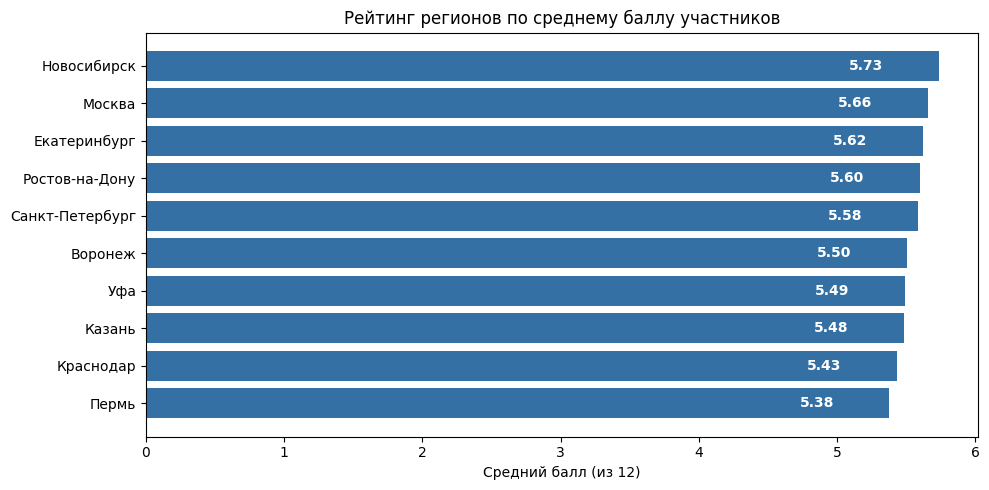

Очищенный файл успешно сохранен: 'olympiad_results_cleaned.csv'


In [7]:
# 1. Сводная аналитика по регионам
regions_summary = (
    df_clean.groupby('region')
    .agg(
        Участников=('student_id', 'count'),
        Средний_балл=('total_score', 'mean'),
        Медиана_баллов=('total_score', 'median'),
        Ср_время_мин=('duration_min', 'mean'),
        Ср_разрывов_связи=('disconnects', 'mean'),
    )
    .reset_index()
    .sort_values(by='Средний_балл', ascending=False)
)

print('Сводная таблица результатов по регионам:')
display(regions_summary.round(2))

# 2. График сравнения регионов по среднему баллу
plt.figure(figsize=(10, 5))
bars = plt.barh(
    regions_summary['region'],
    regions_summary['Средний_балл'],
    color='#3470a3',
)
plt.xlabel('Средний балл (из 12)')
plt.title('Рейтинг регионов по среднему баллу участников')
plt.gca().invert_yaxis()  # лидеры сверху

for bar in bars:
  width = bar.get_width()
  plt.text(
      width - 0.4,
      bar.get_y() + bar.get_height() / 2,
      f'{width:.2f}',
      va='center',
      ha='right',
      color='white',
      fontweight='bold',
  )

plt.tight_layout()
plt.show()

# 3. Сохранение очищенного датасета
df_clean.to_csv('olympiad_results_cleaned.csv', index=False)
print("Очищенный файл успешно сохранен: 'olympiad_results_cleaned.csv'")